Import all of the stuffs and read in documents as well as a textblob example

In [1]:
import pandas as pd
import seaborn as sns
import nltk
import re
import string
import numpy as np
import matplotlib.pyplot as plt
from textblob import TextBlob
from scipy.stats import ks_2samp
from transformers import pipeline

SMALL_SIZE = 3
MEDIUM_SIZE = 10
BIGGER_SIZE = 12
plt.rcParams.update({'figure.max_open_warning': 0})

In [ ]:
df_review = pd.read_csv('data/data_processed/review.csv', index_col=False)
df_review.columns, df_review.shape

(Index(['content', 'stars', 'state', 'category', '2_dig'], dtype='str'),
 (140335, 5))

In [30]:
# clean the data & already performed
# df_review_has_value = df_review[df_review['content'] != None]
# df_review_has_value = df_review_has_value[df_review_has_value['stars'] != None]
# df_review_has_value = df_review_has_value[df_review_has_value['content'] != 'novalue']
# df_review_has_value = df_review_has_value[df_review_has_value['stars'] != 'novalue']
# df_review_has_value = df_review_has_value[df_review_has_value['content'] != 'None']
# df_review_has_value = df_review_has_value[df_review_has_value['stars'] != 'None']
# df_review_has_value = df_review_has_value[df_review_has_value['stars'] != 'None']
# df_review_has_value = df_review_has_value[df_review_has_value['content'].notna()]
# df_review_has_value = df_review_has_value[df_review_has_value['stars'].notna()]
# df_review_has_value['stars'] = df_review_has_value['stars'].astype(int)
# df_review_has_value.shape

## Mixed sentiment examples

In [24]:
txt = "Love the food!! Never had a bad meal. Only complaint is that the ladies behind the counter are just rude. No social skills; just attitudes. I understand one person having an issue; but it's all of them.... They act like everything is an inconvenience...."
blob = TextBlob(txt)
print(blob.sentiment.polarity)

# Access individual word assessments
print(f"{'Word':<15} | {'Polarity':<10} | {'Subjectivity'}")
print("-" * 40)

for word, polarity, subjectivity, assessments in blob.sentiment_assessments.assessments:
    # 'word' is a list because TextBlob handles multi-word expressions
    word_str = ", ".join(word)
    print(f"{word_str:<15} | {polarity:<10.4f} | {subjectivity:.4f}")

calculate_sentiment(txt)

-0.13363095238095238
Word            | Polarity   | Subjectivity
----------------------------------------
love, !, !      | 0.7812     | 0.6000
bad             | -0.7000    | 0.6667
only            | 0.0000     | 1.0000
complaint       | -0.3000    | 0.2000
behind          | -0.4000    | 0.7000
rude            | -0.3000    | 0.6000
no, social      | -0.0167    | 0.0667


-0.523379385471344

In [40]:
txt = "Everything was handled professionally. The shutters were a few days late in coming in; but they were installed recently and look wonderful!"
blob = TextBlob(txt)
print(blob.sentiment.polarity)

# Access individual word assessments
print(f"{'Word':<15} | {'Polarity':<10} | {'Subjectivity'}")
print("-" * 40)

for word, polarity, subjectivity, assessments in blob.sentiment_assessments.assessments:
    # 'word' is a list because TextBlob handles multi-word expressions
    word_str = ", ".join(word)
    print(f"{word_str:<15} | {polarity:<10.4f} | {subjectivity:.4f}")

calculate_sentiment(txt)

0.12
Word            | Polarity   | Subjectivity
----------------------------------------
professionally  | 0.1000     | 0.1000
few             | -0.2000    | 0.1000
late            | -0.3000    | 0.6000
recently        | 0.0000     | 0.2500
wonderful, !    | 1.0000     | 1.0000


0.9689337611198425

## Test for geographical bias

In [ ]:
# view top review states
top_state_review = df_review["state"].value_counts()[0:29]
top_state_review

state_carpe
CA    41967
NY    11425
TX     7710
NV     6839
OR     6817
IL     6390
FL     6266
MA     4889
GA     4030
WA     3201
PA     3070
OH     2750
CO     2543
IN     2467
MI     2180
DC     2135
MO     2032
WI     1820
MN     1706
NC     1570
NJ     1563
VA     1536
CT     1412
UT     1281
TN     1258
KY     1205
MD     1197
AZ     1172
NM      933
Name: count, dtype: int64

In [ ]:
from scipy import stats
p_value = []
for _ in range(20) :
    groups = [group['stars'].values for name, group in df_review[["state", "stars"]].sample(1000).groupby('state')]
    h_stat, p_kw = stats.kruskal(*groups)
    p_value.append(p_kw)
np.mean(p_value)

np.float64(0.005915839658351418)

In [ ]:
def average_polarity(review_content: str):
    '''
    calculate polarity of each review
    '''
    # create a textblob object
    # this will directly seperate a review into sentences
    blob = TextBlob(review_content) 
    return blob.sentiment.polarity

p_value1, p_value2 = [], []
for _ in range(20) :
    df = df_review[["state", "stars", "content"]].sample(n=1000)
    df['polarity_score'] = df['content'].apply(lambda r: average_polarity(r))
    from sklearn.linear_model import LinearRegression
    lm1 = LinearRegression()
    lm1.fit(df['polarity_score'].values.reshape(-1, 1), df["stars"].values)
    df["residual_1"] = df["stars"] - lm1.predict(df['polarity_score'].values.reshape(-1, 1))
    groups1 = [group['residual_1'].values for name, group in df[["state", "residual_1"]].groupby('state')]
    h_stat1, p_kw1 = stats.kruskal(*groups1)
    p_value1.append(p_kw1)
    
    lm2 = LinearRegression()
    lm2.fit(df["stars"].values.reshape(-1, 1), df['polarity_score'].values)
    df["residual_2"] = df["polarity_score"] - lm2.predict(df['stars'].values.reshape(-1, 1))
    groups2 = [group['residual_2'].values for name, group in df[["state", "residual_2"]].groupby('state')]
    h_stat2, p_kw2 = stats.kruskal(*groups2)
    p_value2.append(p_kw2)

np.mean(p_value1), np.mean(p_value2)

(np.float64(0.04087331163118871), np.float64(0.2271350463398416))

In [ ]:
# section review by state
review_by_state = {}
for s in top_state_review.keys():
    review_by_state[s] = df_review[df_review["state"] == s]

In [ ]:
def calculate_polarity(review_content: str):
    '''
    calculate polarity of each review
    '''
    # create a textblob object
    # this will directly seperate a review into sentences
    blob = TextBlob(review_content) 
    negativity_count = 0
    polarity = []
    average_polarity = 0
    max_min_polarity = 0
    bipolar_polarity = 0
    average_polarity = blob.sentiment.polarity

    return [average_polarity, max_min_polarity, bipolar_polarity]

def calculate_sentiment(review_content: str):
    sentiment_pipeline = pipeline("sentiment-analysis")
    sentiment = sentiment_pipeline(review_content)[0]
    score = sentiment["score"] if sentiment["label"] == "POSITIVE" else -1 * sentiment["score"]
    return score

def plot_star_and_score(df, state):
    '''
    plotting stuff, not too interesting
    '''
    fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(20, 5))
    
    sns.histplot(data=df['stars'].astype(int), ax = axes[0])
    axes[0].set_title('Star Distribution')
    axes[0].set_xlabel('Star Level')
    
    sns.histplot(data=df['average_polarity'],color = 'orange',ax = axes[1], bins=100)
    axes[1].set_title('Average Polarity Score Distribution')
    axes[1].set_xlabel('Polarity Score')
    
    """sns.histplot(df['max_min_polarity'],color = 'Green',ax = axes[1][0], bins=100)
    axes[1][0].set_title('Max-Min Polarity Score Distribution')
    axes[1][0].set_xlabel('Polarity Score')
    
    sns.histplot(df['bipolar_polarity'],color = 'Red',ax = axes[1][1], bins=100)
    axes[1][1].set_title('Bipolar Polarity Score Distribution')
    axes[1][1].set_xlabel('Polarity Score')"""
    fig.suptitle('plot of {}'.format(state), fontsize=16)

    plt.tight_layout()
    
    
def plot_state_over_lap(df, star=None):
    fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(20, 6))
    if star != None:
        df = df[df['stars']==int(star)]
    sns.histplot(data=df, ax = axes[0], x='stars', hue='state', multiple="dodge", shrink=.8)
    axes[0].set_title('Star Distribution')
    axes[0].set_xlabel('Star Level')
    
    sns.histplot(data=df,ax = axes[1], bins=100, x='average_polarity', hue='state')
    axes[1].set_title('Average Polarity Score Distribution')
    axes[1].set_xlabel('Polarity Distribution')
    plt.tight_layout()

plt.rcParams.update({'font.size':6, 
                    'axes.titlesize':10,
                    'axes.labelsize':10,
                    'xtick.labelsize':10,
                    'ytick.labelsize':10,
                    'legend.fontsize':6})


# allow only 3 colors
# controls default text sizes
def plot_pair_by_state_and_star(pair1, pair2, field = 'State', star_column = "stars", start_star=1, end_star=5, star_list = [1,5]):
    review_by=None
    if field == 'State':
        review_by = review_by_state
        field_name='state'
        color_mapping = {
            "CA": "blue",
            "FL": "orange",
            "NJ": "red"
        }
        color_palette = {pair1: color_mapping[pair1], pair2: color_mapping[pair2]}
        
    if field == 'Naics':
        review_by = review_by_naics
        field_name='category'
        color_mapping = {
            72: "blue",
            45: "orange",
            51: "red"
        }
        color_palette = {
            review_by_naics[pair1]["category"].unique()[0]: color_mapping[pair1], 
            review_by_naics[pair2]["category"].unique()[0]: color_mapping[pair2]
        }
        
    if star_list == None:
        star_list = range(start_star,end_star + 1)  
        
    fig, axes = plt.subplots(nrows=len(star_list), ncols=1)#, figsize=(4, 2.5*len(star_list)), dpi=600)
    
    for index, star in enumerate(star_list):
        
        review_pair1 = review_by[pair1][review_by[pair1][star_column] == star].sample(n = 1000, replace=True)
        review_pair1['polarity_score'] = review_pair1['content'].apply(lambda r: calculate_polarity(r))
        star_pair1= \
            pd.DataFrame(review_pair1['polarity_score'].to_list(), columns = ['average_polarity', 'max_min_polarity', 'bipolar_polarity'])
        star_pair1[star_column] = review_pair1[star_column].values
        star_pair1[field] = review_pair1[field_name].values
        
        review_pair2 = review_by[pair2][review_by[pair2][star_column] == star].sample(n = 1000, replace=True)
        review_pair2['polarity_score'] = review_pair2['content'].apply(lambda r: calculate_polarity(r))
        star_pair2= \
            pd.DataFrame(review_pair2['polarity_score'].to_list(), columns = ['average_polarity', 'max_min_polarity', 'bipolar_polarity'])
        star_pair2[star_column] = review_pair2[star_column].values
        star_pair2[field] = review_pair2[field_name].values
        tot_df = pd.concat([star_pair1, star_pair2])
        
        print('K-S test result: ', ks_2samp(star_pair1['average_polarity'],star_pair2['average_polarity'] ))
        # palette_tot = sns.color_palette(palette=["blue", "orange", "red"])
        # sns.set_palette(palette = {color_mapping[pair1], color_mapping[pair2]})
        
        sns.histplot(
            data=tot_df, bins=100, x='average_polarity', kde=True, ax=axes[index], line_kws=dict(linewidth=2),
            hue=field, palette = color_palette
        )
        
        axes[index].set_title('Average Polarity Score Distribution for {} star Reviews'.format(star))
        axes[index].set_xlabel('Polarity Distribution')
        axes[index].set_xlim(-1.1, 1.1)
        axes[index].set_ylim(0, 100)
            
        
    plt.tight_layout()
        
    fig.savefig(fname=('fig/{s1}_{s2}_polarity_from_{star1}_to_{star2}.pdf'.format(s1=pair1, s2=pair2, star1=start_star, star2=end_star)))

## Explore star distribution by state

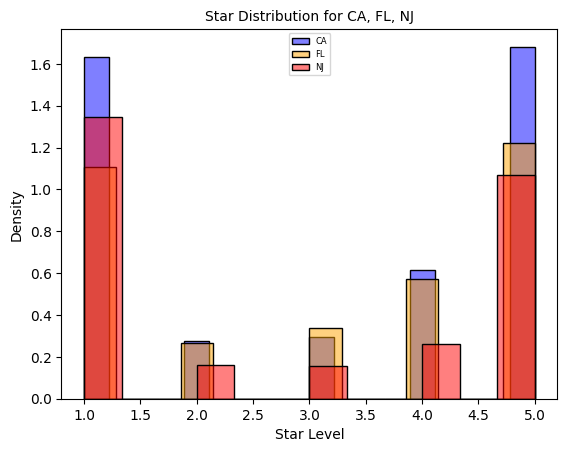

In [9]:
plt.figure()
sns.histplot(review_by_state["CA"].stars, color = "blue", alpha = 0.5, label = "CA", stat = "density")
sns.histplot(review_by_state["FL"].stars, color = "orange", alpha = 0.5, label = "FL", stat = "density")
sns.histplot(review_by_state["NJ"].stars, color = "red", alpha = 0.5, label = "NJ", stat = "density")
plt.xlabel('Star Level')
plt.ylabel('Density')
plt.title('Star Distribution for CA, FL, NJ')
plt.legend()
plt.grid(False)
plt.show()

## Explore review polarity group by state

K-S test result:  KstestResult(statistic=0.093, pvalue=0.00034775170271509687, statistic_location=-0.021518759018759024, statistic_sign=-1)
K-S test result:  KstestResult(statistic=0.198, pvalue=1.4811534595157654e-17, statistic_location=0.36562500000000003, statistic_sign=1)


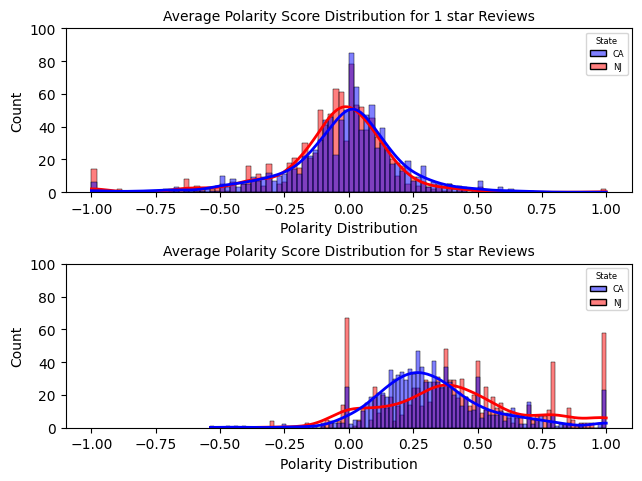

In [10]:
plot_pair_by_state_and_star('CA','NJ')
#plot_pair_by_state_and_star('CA','NJ', start_star=1, end_star=1)

K-S test result:  KstestResult(statistic=0.103, pvalue=4.872295384883887e-05, statistic_location=0.12142857142857141, statistic_sign=-1)
K-S test result:  KstestResult(statistic=0.128, pvalue=1.4776675436423948e-07, statistic_location=0.33333333333333326, statistic_sign=1)


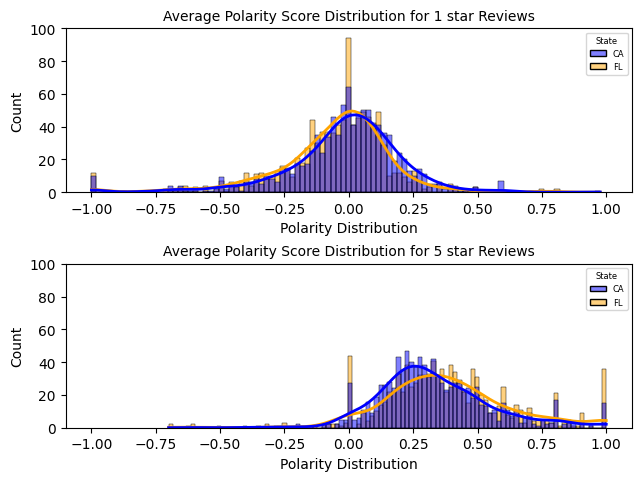

In [11]:
plot_pair_by_state_and_star('CA', 'FL')

## Neural LM-based sentiment

In [ ]:
def average_polarity(review_content: str):
    '''
    calculate polarity of each review
    '''
    # create a textblob object
    # this will directly seperate a review into sentences
    blob = TextBlob(review_content) 
    return blob.sentiment.polarity
    

from transformers import pipeline, AutoTokenizer

sentiment_pipeline = pipeline(
    "sentiment-analysis", 
    model = "cardiffnlp/twitter-roberta-base-sentiment-latest",
    # device = -1
)
tokenizer = AutoTokenizer.from_pretrained("siebert/sentiment-roberta-large-english")

def _chunk_text_by_tokens(text: str, chunk_size: int = 480):
    token_ids = tokenizer(text, add_special_tokens=False, truncation=False)["input_ids"]

    if len(token_ids) <= chunk_size:
        return [text]

    chunks = []
    for i in range(0, len(token_ids), chunk_size):
        chunk_ids = token_ids[i:i + chunk_size]
        chunks.append(tokenizer.decode(chunk_ids, skip_special_tokens=True))
    return chunks

def calculate_sentiment(review_content: str):
    """
    Returns sentiment score in [-1, 1].
    Long text is chunked, then combined with token-weighted averaging.
    """
    if not isinstance(review_content, str) or not review_content.strip():
        return 0.0

    try:
        chunks = _chunk_text_by_tokens(review_content)

        weighted_sum = 0.0
        total_tokens = 0

        for chunk in chunks:
            result = sentiment_pipeline(chunk, truncation=True, max_length=512)[0]
            label = str(result["label"]).upper()
            score = float(result["score"])
            signed_score = score if "POS" in label else -score

            token_count = len(tokenizer(chunk, add_special_tokens=False)["input_ids"])
            weighted_sum += signed_score * token_count
            total_tokens += token_count

        return weighted_sum / total_tokens if total_tokens else 0.0
    except Exception:
        return 0.0

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


config.json:   0%|          | 0.00/687 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/256 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

K-S test result:  KstestResult(statistic=np.float64(0.059), pvalue=np.float64(0.06153429181321559), statistic_location=np.float64(-0.9117372632026672), statistic_sign=np.int8(-1))
K-S test result:  KstestResult(statistic=np.float64(0.042), pvalue=np.float64(0.34112475112661245), statistic_location=np.float64(0.7179358601570129), statistic_sign=np.int8(-1))
K-S test result:  KstestResult(statistic=np.float64(0.059), pvalue=np.float64(0.06153429181321559), statistic_location=np.float64(-0.9317283034324646), statistic_sign=np.int8(-1))
K-S test result:  KstestResult(statistic=np.float64(0.091), pvalue=np.float64(0.0005028776494501317), statistic_location=np.float64(0.9301446080207825), statistic_sign=np.int8(1))


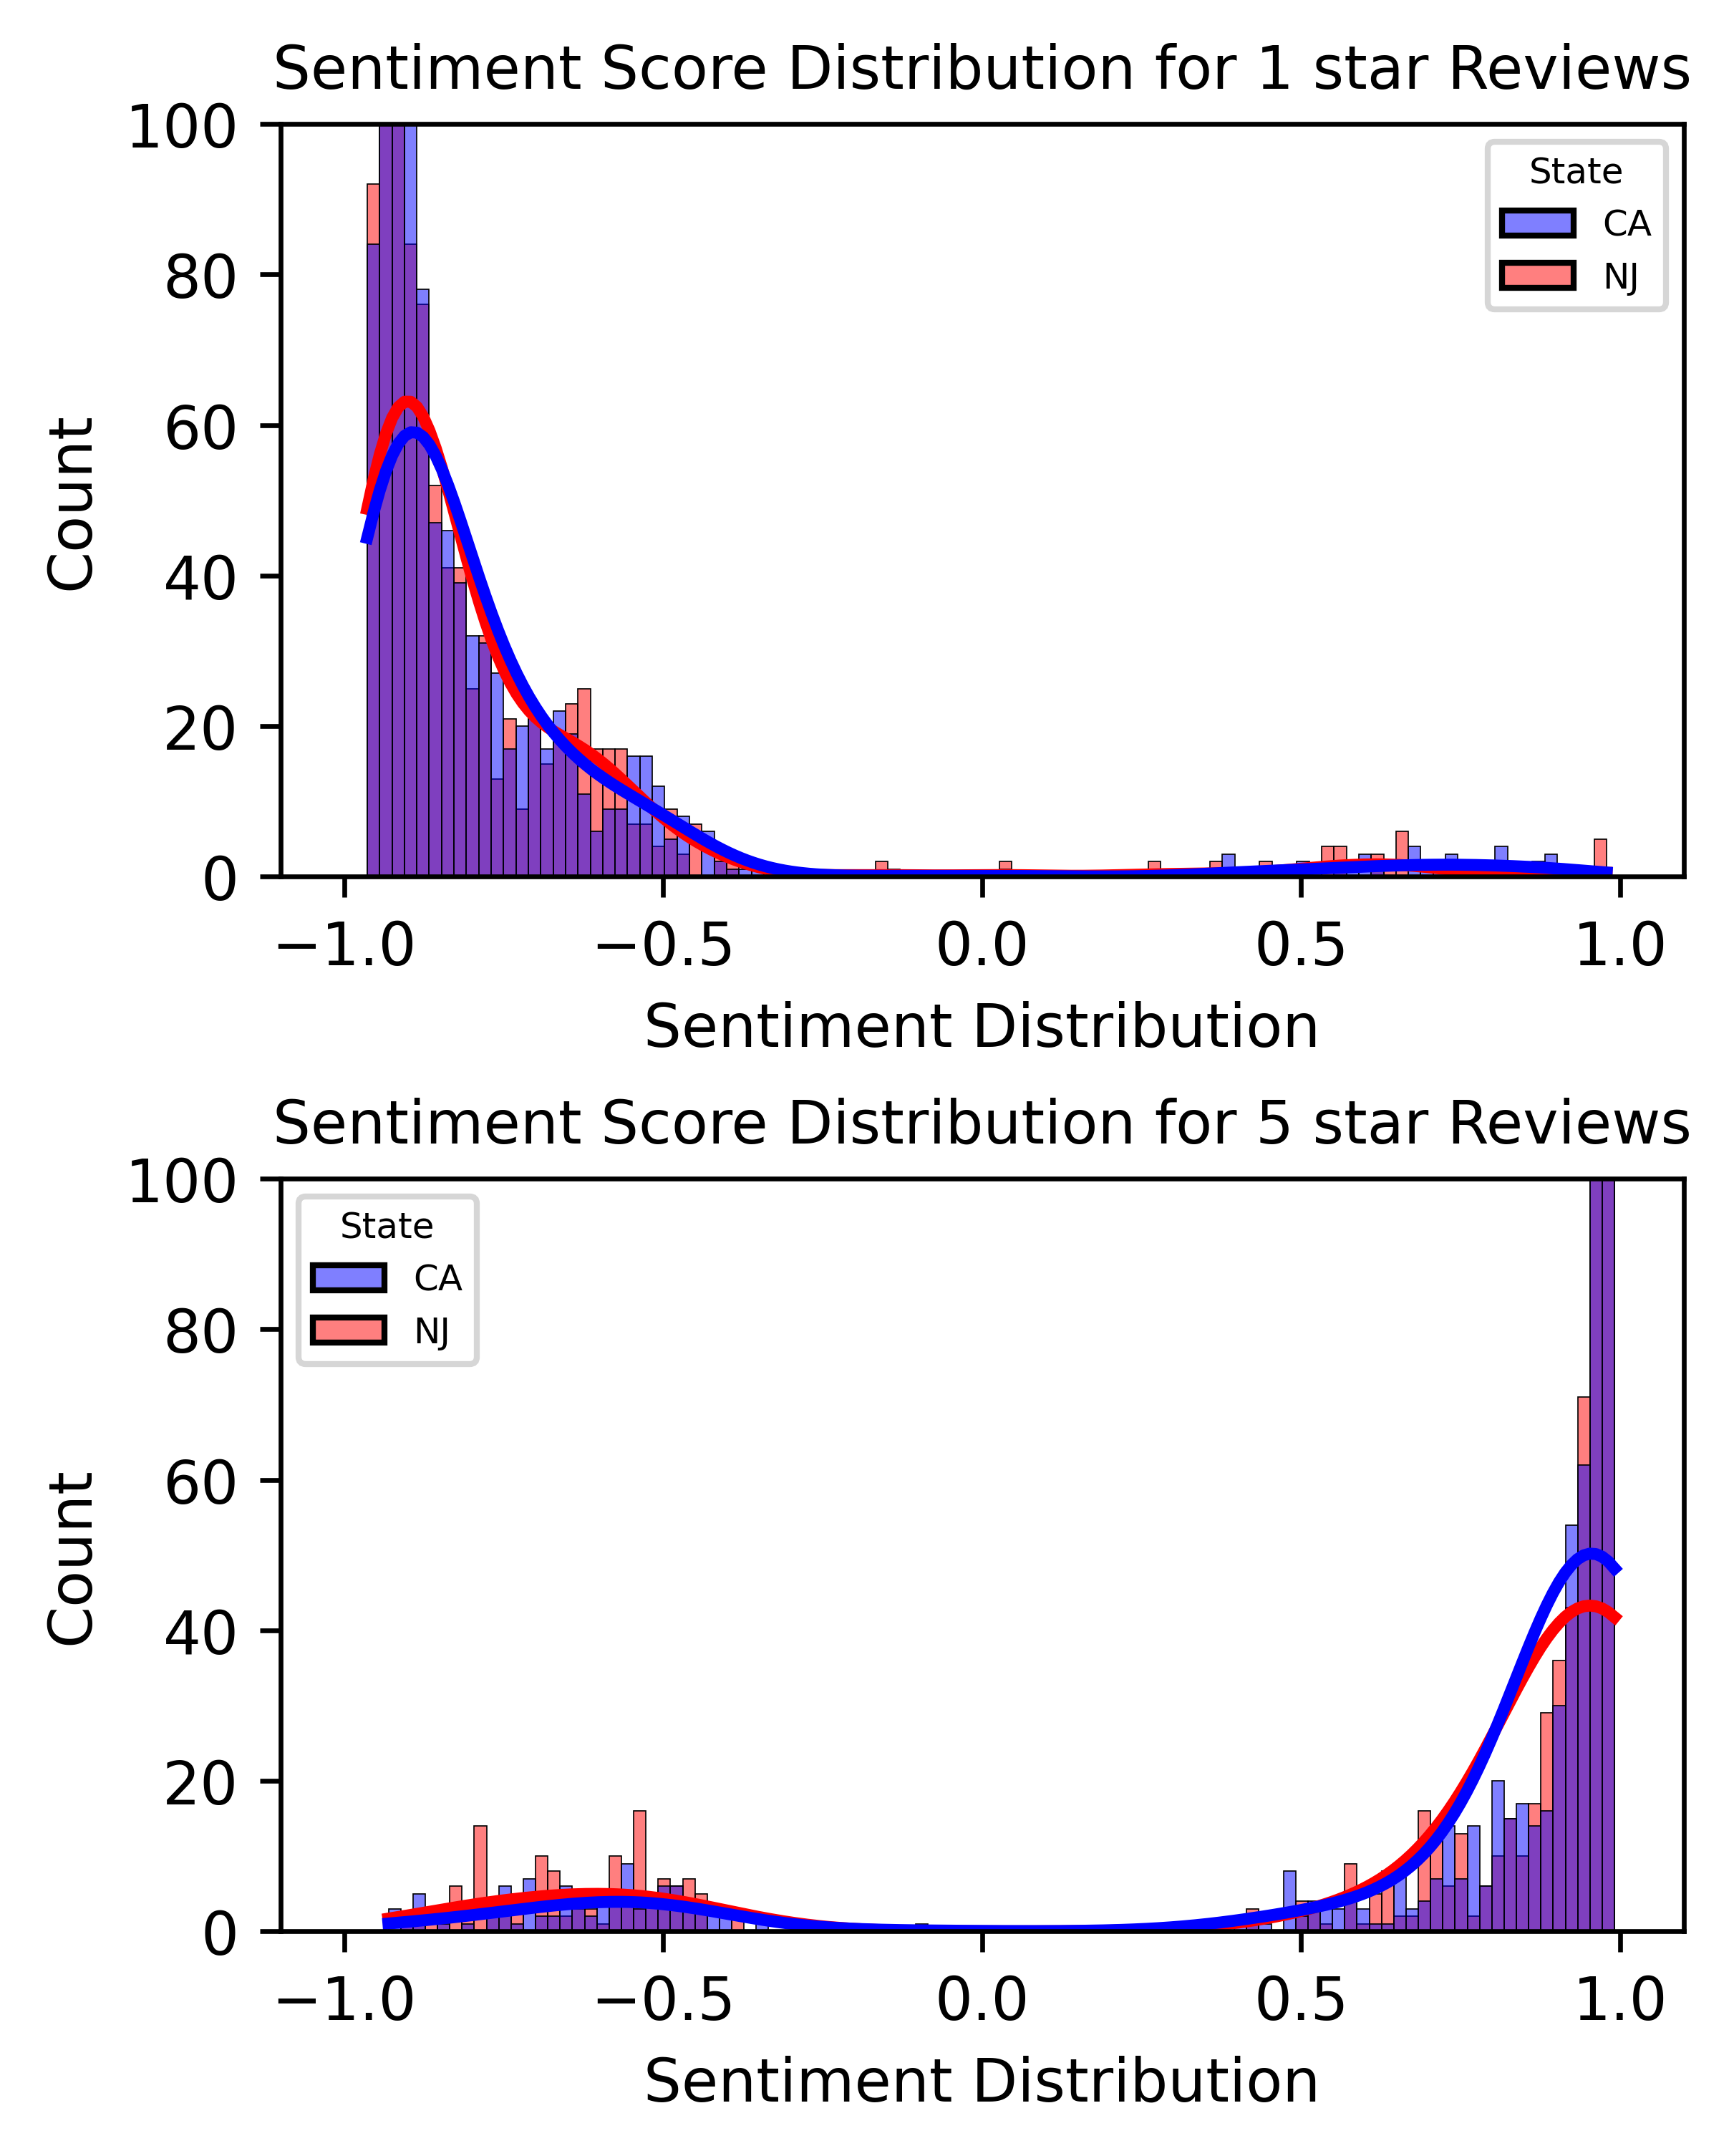

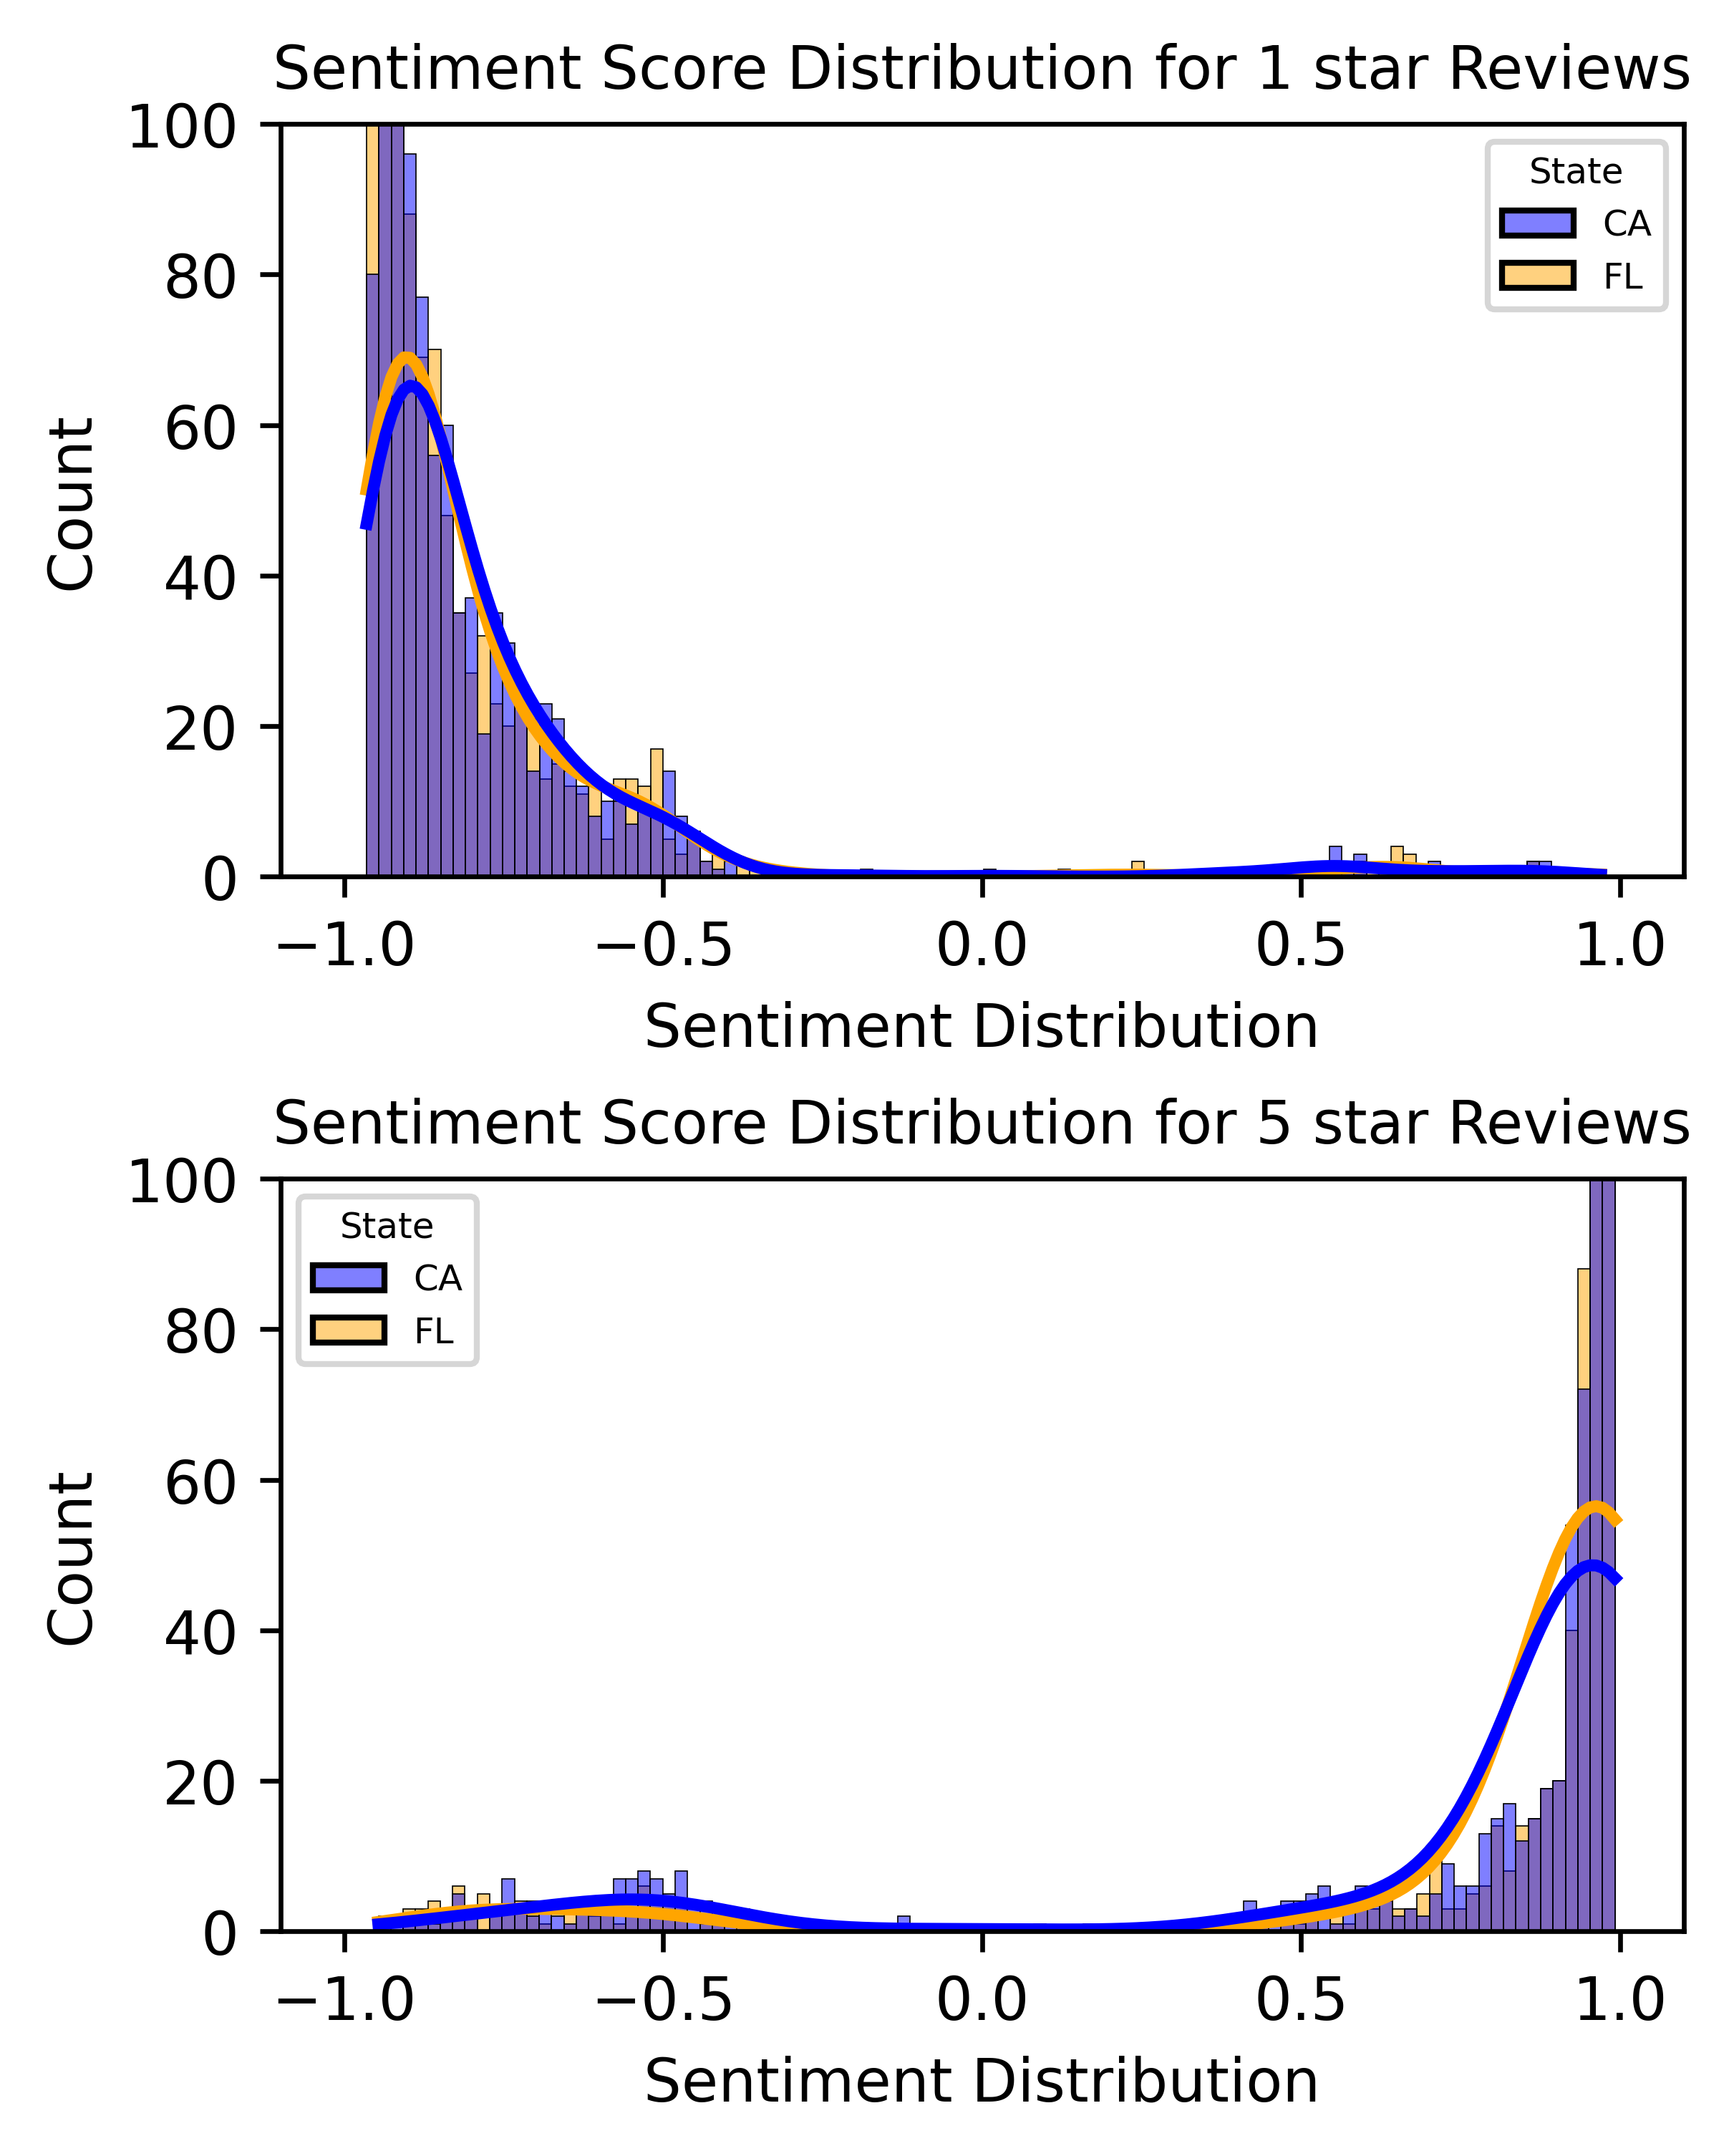

In [ ]:
def plot_pair_by_state_and_star(pair1, pair2, field = 'State', star_column = "stars", start_star=1, end_star=5, star_list = [1,5]):
    review_by=None
    if field == 'State':
        review_by = review_by_state
        field_name='state'
        color_mapping = {
            "CA": "blue",
            "FL": "orange",
            "NJ": "red"
        }
        color_palette = {pair1: color_mapping[pair1], pair2: color_mapping[pair2]}
        
    if field == 'Naics':
        review_by = review_by_naics
        field_name='category'
        color_mapping = {
            72: "blue",
            45: "orange",
            51: "red"
        }
        color_palette = {
            review_by_naics[pair1]["category"].unique()[0]: color_mapping[pair1], 
            review_by_naics[pair2]["category"].unique()[0]: color_mapping[pair2]
        }
        
    if star_list == None:
        star_list = range(start_star,end_star + 1)  
        
    fig, axes = plt.subplots(nrows=len(star_list), ncols=1, figsize=(4, 5), dpi=600)
    
    for index, star in enumerate(star_list):
        
        review_pair1 = review_by[pair1][review_by[pair1][star_column] == star].sample(n = 1000, replace=True)
        review_pair1['sentiment_score'] = review_pair1['content'].apply(lambda r: calculate_sentiment(r))
        # review_pair1[star_column] = review_pair1[star_column].values
        review_pair1[field] = review_pair1[field_name].values
        
        review_pair2 = review_by[pair2][review_by[pair2][star_column] == star].sample(n = 1000, replace=True)
        review_pair2['sentiment_score'] = review_pair2['content'].apply(lambda r: calculate_sentiment(r))
        # review_pair2[star_column] = review_pair2[star_column].values
        review_pair2[field] = review_pair2[field_name].values
        tot_df = pd.concat([review_pair1, review_pair2])
        
        print('K-S test result: ', ks_2samp(review_pair1['sentiment_score'],review_pair2['sentiment_score'] ))
        # palette_tot = sns.color_palette(palette=["blue", "orange", "red"])
        # sns.set_palette(palette = {color_mapping[pair1], color_mapping[pair2]})
        
        sns.histplot(
            data=tot_df, bins=100, x='sentiment_score', kde=True, ax=axes[index], line_kws=dict(linewidth=2),
            hue=field, palette = color_palette
        )
        
        axes[index].set_title('Sentiment Score Distribution for {} star Reviews'.format(star))
        axes[index].set_xlabel('Sentiment Distribution')
        axes[index].set_xlim(-1.1, 1.1)
        axes[index].set_ylim(0, 100)
            
        
    plt.tight_layout()
        
    fig.savefig(fname=('fig/{s1}_{s2}_sentiment_from_{star1}_to_{star2}_LM.pdf'.format(s1=pair1, s2=pair2, star1=start_star, star2=end_star)))

plot_pair_by_state_and_star('CA','NJ')
plot_pair_by_state_and_star('CA', 'FL')